# LeetCode #170: Two Sum III - Data structure design

https://leetcode.com/problems/two-sum-iii-data-structure-design/

## Comparison of Approaches
| Approach | Time (add/find) | Space |
|---|---|---|
| Hash Map ★ | O(1) add / O(n) find | O(n) |
| Sorted List | O(n) add / O(n) find | O(n) |

## Understanding the Methods
### Sorted List
Keep a sorted list; add inserts in sorted order O(n); find uses two pointers O(n).

### Optimal: Hash Map ★
Store number frequencies in a hash map. add() is O(1). find(value) iterates all keys: for each key k, check if complement = value - k exists. If complement == k, need count >= 2; otherwise need count >= 1.

## Solutions
### C#

In [ ]:
public class TwoSum {
    private Dictionary<int, int> counts = new();

    public void Add(int number) {
        counts[number] = counts.GetValueOrDefault(number, 0) + 1;
    }

    public bool Find(int value) {
        foreach (var kvp in counts) {
            int complement = value - kvp.Key;
            if (complement == kvp.Key) {
                if (kvp.Value >= 2) return true;
            } else if (counts.ContainsKey(complement)) {
                return true;
            }
        }
        return false;
    }
}

### Python

In [ ]:
from collections import defaultdict

class TwoSum:
    def __init__(self):
        self.counts = defaultdict(int)

    def add(self, number: int) -> None:
        self.counts[number] += 1

    def find(self, value: int) -> bool:
        for num, cnt in self.counts.items():
            complement = value - num
            if complement == num:
                if cnt >= 2:
                    return True
            elif complement in self.counts:
                return True
        return False

### Go

In [ ]:
package main

import "fmt"

type TwoSum struct {
    counts map[int]int
}

func Constructor() TwoSum {
    return TwoSum{counts: map[int]int{}}
}

func (ts *TwoSum) Add(number int) {
    ts.counts[number]++
}

func (ts *TwoSum) Find(value int) bool {
    for k, v := range ts.counts {
        complement := value - k
        if complement == k {
            if v >= 2 {
                return true
            }
        } else if _, ok := ts.counts[complement]; ok {
            return true
        }
    }
    return false
}

func main() {
    ts := Constructor()
    ts.Add(1); ts.Add(3); ts.Add(5)
    fmt.Println(ts.Find(4)) // true (1+3)
    fmt.Println(ts.Find(7)) // false
}

### Rust

In [ ]:
use std::collections::HashMap;

pub struct TwoSum {
    counts: HashMap<i32, i32>,
}

impl TwoSum {
    pub fn new() -> Self {
        TwoSum { counts: HashMap::new() }
    }

    pub fn add(&mut self, number: i32) {
        *self.counts.entry(number).or_insert(0) += 1;
    }

    pub fn find(&self, value: i32) -> bool {
        for (&k, &v) in &self.counts {
            let complement = value - k;
            if complement == k {
                if v >= 2 { return true; }
            } else if self.counts.contains_key(&complement) {
                return true;
            }
        }
        false
    }
}

## Examples

### 1. Common Case — Add Then Find a Pair
**Input:** `add(1); add(3); add(5); find(4); find(7)`
The map becomes $\{1{:}1,3{:}1,5{:}1\}$. $find(4)$ sees complement $4-1=3$ present $\to$ `true`; $find(7)$ finds no complement among the keys $\to$ `false`.

### 2. Slightly Complex — The Duplicate Rule
**Input:** `add(2); find(4); add(2); find(4)`
With one $2$, $find(4)$ needs $2+2$ but count is only $1 \to$ `false`. After a second $add(2)$ the count is $2$, so the self-pair is valid $\to$ `true`.

### 3. Edge Case: Time Factor — find Scans Every Key
**Input:** `add(1..5); find(9)`
$add$ is $O(1)$, but $find$ walks all stored keys: $9-4=5$ exists, returning `true` only after a linear scan — $O(n)$ per query.

### 4. Edge Case: Space Factor — Map Grows with Distinct Values
**Input:** `add(1); add(2); add(3); find(100)`
Three distinct keys occupy $O(n)$ space; $find(100)$ finds no complement and returns `false`.

### 5. Almost-Impossible but Plausible — Negatives and Zero
**Input:** `add(-3); add(3); add(0); find(0); find(6)`
$find(0)$ pairs $-3+3 \to$ `true`. $find(6)$ would need another $3$ (count $1$) or an absent key, so it returns `false`.


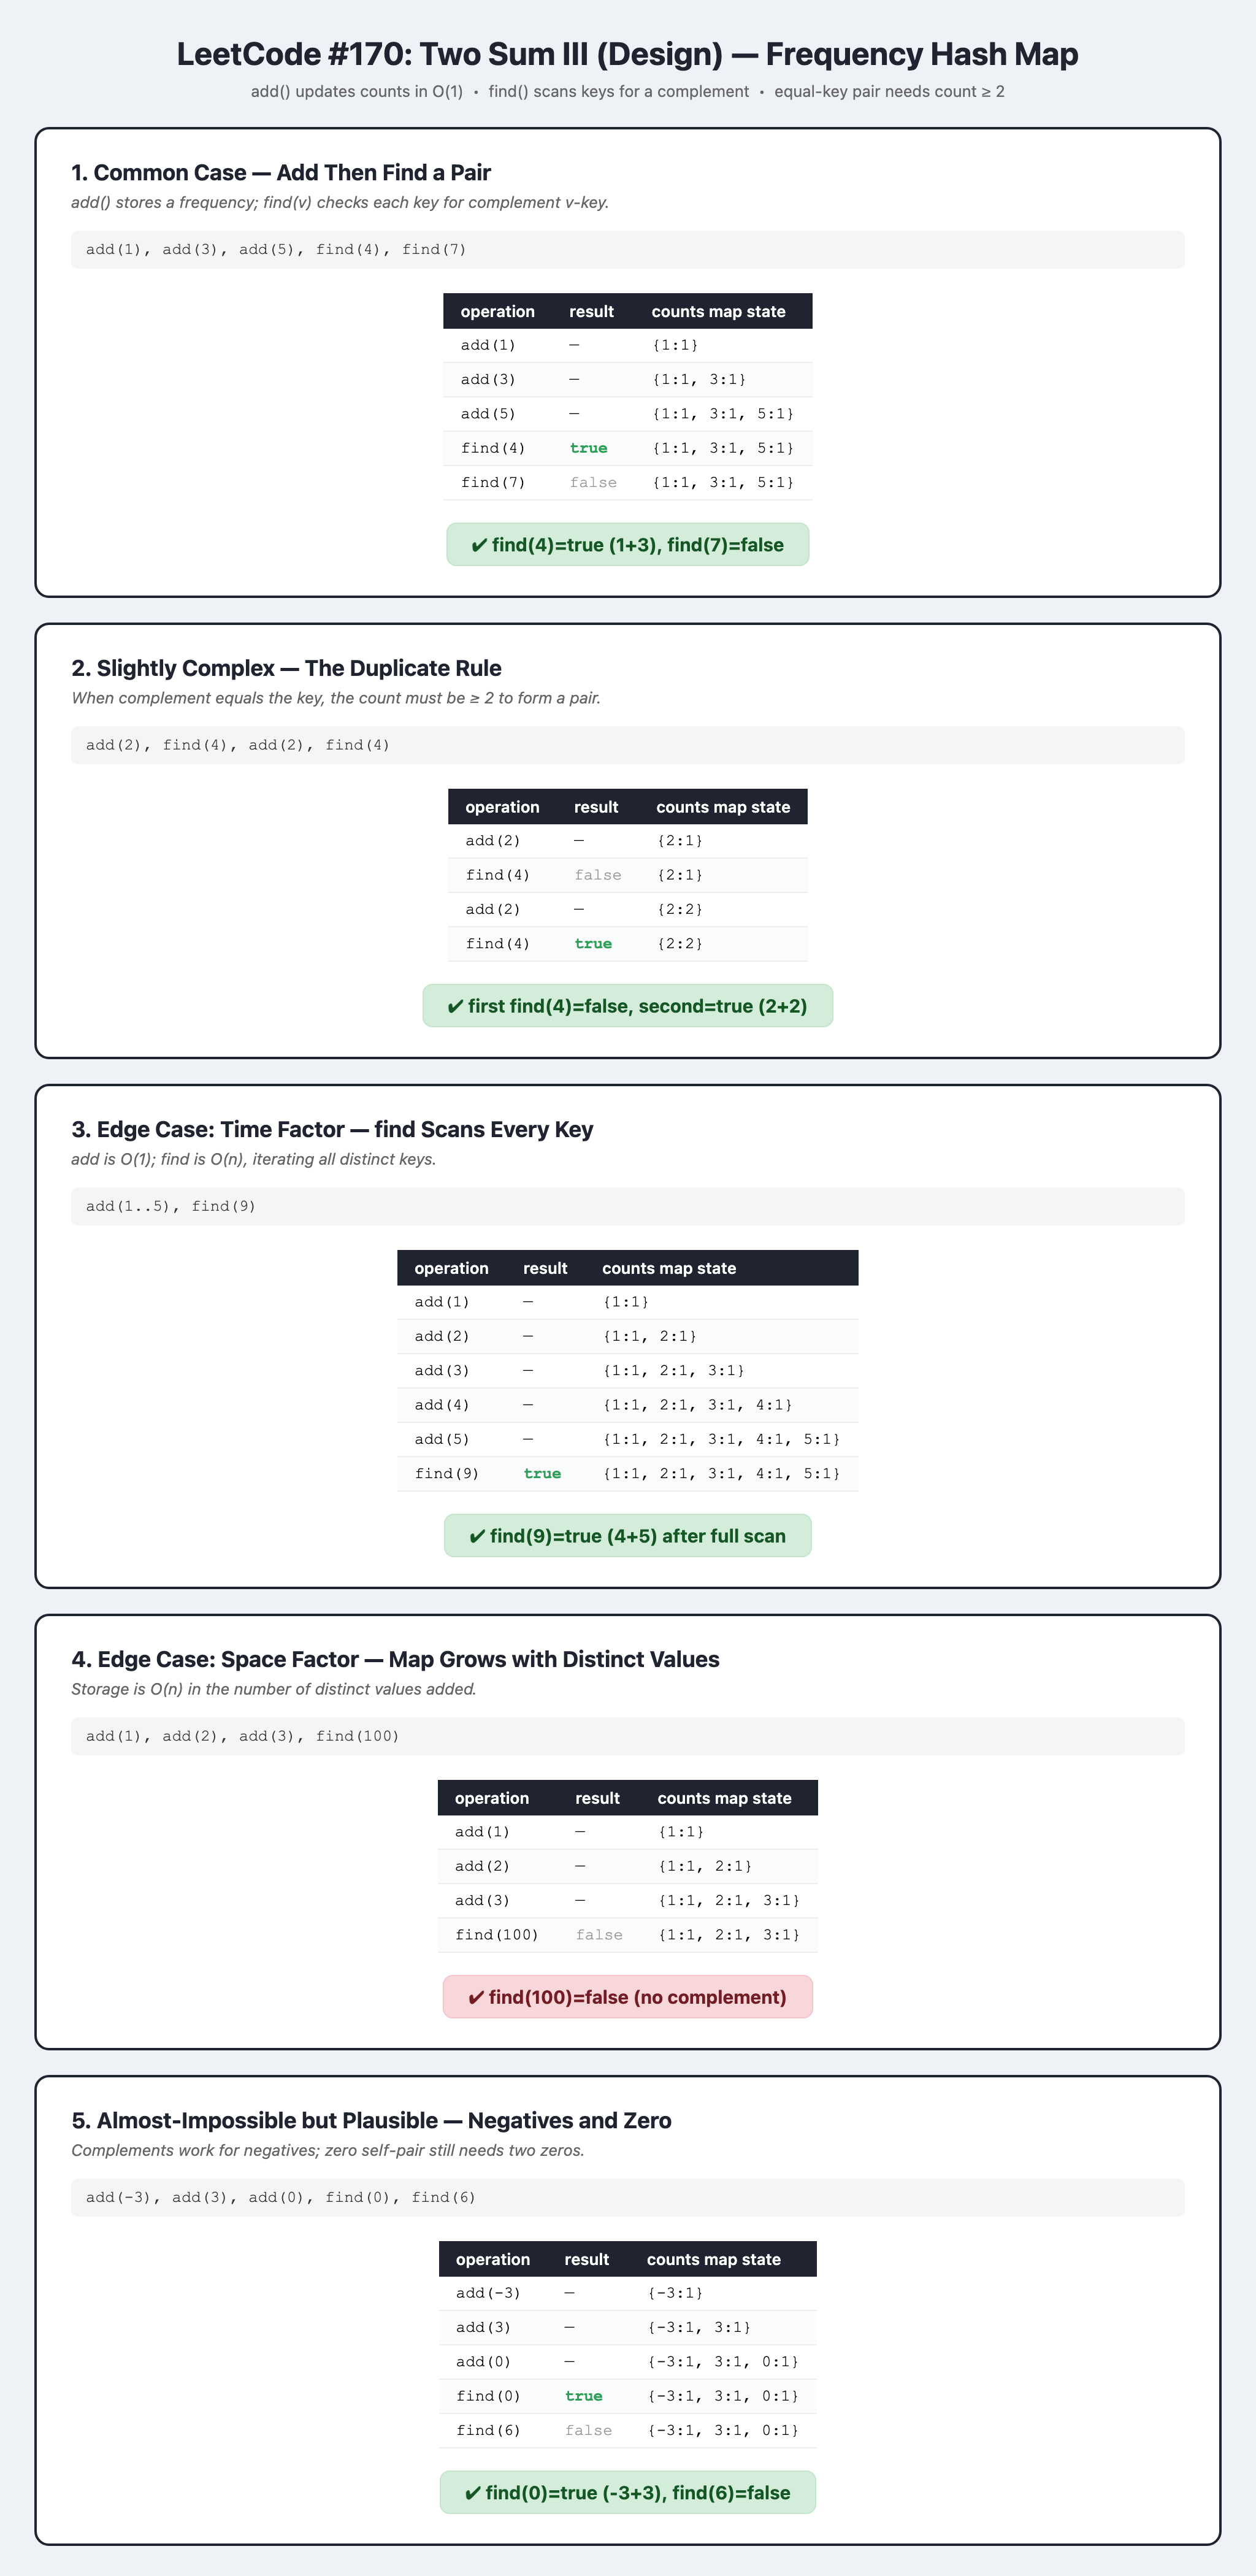